# [Agent] NB2b — GRPO Planner SFT / GRPO Training (v2)
evaluator NB2(`02_agent_sft_grpo_training.ipynb`)와 동일한 구조를 따르되, 학습
재료가 `training_data_*.jsonl`이 아니라 **oracle rollout parquet**이라는 점이
다르다.

★ v2 변경사항: evaluator NB2의 검증/시각화 섹션(Section 8~10 통계, G3 식별
가능성 probe, 학습 후 confusion matrix)을 최대한 그대로 planner에 이식했다.
evaluator 전용(wm_type_gt 텍스트 grounding, ni/spread 진술 채점 등)은 개념만
가져오고 planner의 실제 데이터(oracle reward/action)에 맞게 다시 짰다 —
그대로 복사해서 될 만큼 데이터 구조가 같지 않았다(evaluator는 텍스트 채점,
planner는 오라클 lookup 기반이라 GRPO reward 자체의 계산 방식이 다름).

★ [버그 수정 반영] persona/neighbors가 아직 JSON 문자열(디코드 전)이어도
안전하게 처리하도록 오라클 로드 셀을 방어적으로 고쳤다 — 지난 turn에 노트북
03의 precheck 셀에서 실행 순서 때문에 오탐이 났던 것과 동일한 함정을 여기서도
미리 막았다.


## Section 0: 환경

In [146]:
# GCP 인증 — gcsfuse 마운트를 위해 여전히 필요
from google.colab import auth
auth.authenticate_user()
print('✅ GCP 인증 완료 (gcsfuse 마운트용)')

import os
!echo "deb http://packages.cloud.google.com/apt gcsfuse-`lsb_release -c -s` main" | sudo tee /etc/apt/sources.list.d/gcsfuse.list
!curl https://packages.cloud.google.com/apt/doc/apt-key.gpg | sudo apt-key add -
!sudo apt-get update
!sudo apt-get install -y -q gcsfuse

# ★ oracle_extractor.py가 실제로 쓰는 버킷(fraud_ecommm, m 3개)을 직접 마운트한다.
#   common/*.py(config/prompts/data_io/schema)가 이 버킷에 없다면 COMMON_SRC를
#   실제 위치로 바꿀 것 (예: 별도 마운트 두 개 사용).
GCS_BUCKET  = "fraud_ecommm"
GCP_PROJECT = "kakaoo-501107"
MOUNT_POINT = "/content/gcs_mount"

os.makedirs(MOUNT_POINT, exist_ok=True)
!gcsfuse --implicit-dirs --key-file="" {GCS_BUCKET} {MOUNT_POINT} 2>&1 | tail -3

result = os.listdir(MOUNT_POINT)
print(f'✅ GCS 마운트 완료: {MOUNT_POINT}')
print(f'   최상위 폴더: {result[:8]}')

!pip install -q \
    trl peft transformers accelerate datasets \
    bitsandbytes scikit-learn matplotlib

print("✅ 설치 완료")


✅ GCP 인증 완료 (gcsfuse 마운트용)
deb http://packages.cloud.google.com/apt gcsfuse-jammy main
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0Warning: apt-key is deprecated. Manage keyring files in trusted.gpg.d instead (see apt-key(8)).
100  1022  100  1022    0     0  15111      0 --:--:-- --:--:-- --:--:-- 15253
OK
Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:4 http://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Hit:5 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:7 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com

## Bootstrap: 공통 모듈 로드 (evaluator와 동일 — prompts.py 재사용을 위해 필요)

In [147]:
# ============================================================
# 공통 모듈(common/*.py) 로드 — evaluator NB2 cell 4와 동일 패턴.
# ============================================================
import sys, os, shutil, importlib

COMMON_SRC = "/content/gcs_mount/tree-search/analyzer_ft/common"   # ★ 실제 위치 확인
COMMON_DST = "/content/common"
shutil.rmtree(COMMON_DST, ignore_errors=True)
shutil.copytree(COMMON_SRC, COMMON_DST)
if COMMON_DST not in sys.path:
    sys.path.insert(0, COMMON_DST)

import config, prompts, data_io, schema
for _m in (config, prompts, data_io, schema):
    importlib.reload(_m)
print("✅ common 모듈 로드:", [m.__name__ for m in (config, prompts, data_io, schema)])

assert hasattr(prompts, "build_planner_user_prompt"), (
    "prompts.py에 build_planner_user_prompt가 없습니다 — 이번 turn에 추가한 "
    "prompts.py를 COMMON_SRC에 먼저 업로드하세요.")
print("✅ prompts.build_planner_user_prompt 확인됨")

from config import *
EXPERIMENT_CASE = globals().get("EXPERIMENT_CASE", "pca_64_k100")
mode = "agent"
globals().update(config.set_data(mode=mode))
config.ensure_dirs()
globals().update(data_io.load_all(mode=mode))   # bind_runtime() 포함 — DIST_P50/IQR 등 주입
print("✅ 런타임 준비 완료")


✅ common 모듈 로드: ['config', 'prompts', 'data_io', 'schema']
✅ prompts.build_planner_user_prompt 확인됨
✅ data_io.load_all(mode=agent)
   personas=100  coreset_map=122,810
   test=28,302  normal/abnormal=14151/14151
   dist p25/p50/p75=1.264/1.448/1.651  IQR=0.387
✅ 런타임 준비 완료


## Section P-10: Oracle 로드 + 통계 검증 + Planner Prompt 재구성 + 균등 샘플링

In [148]:
# ============================================================
# [Oracle] gcsfuse 마운트 경로에서 직접 로드
# ★ [버그 수정] persona/neighbors가 JSON 문자열이든 이미 dict/list든 안전하게
#   처리한다 — 이전에 이 디코드 루프를 실행 안 하고 precheck을 돌려서
#   "persona 키가 비었다"는 오탐이 났던 적이 있다(실제로는 문자열 상태였을
#   뿐 데이터는 정상). _ensure_decoded()가 이 함정을 원천 차단한다.
# ============================================================
import pandas as pd, json as _json, numpy as np

ORACLE_EXPERIMENT_CASE   = EXPERIMENT_CASE
ORACLE_PERCOLATE_VERSION = "v1"
ORACLE_CORESET_PCT       = 100
ORACLE_DATE               = "0811"

_oracle_path = (
    f"/content/gcs_mount/oracle/{ORACLE_EXPERIMENT_CASE}/"
    f"query_{ORACLE_PERCOLATE_VERSION}_pct_{ORACLE_CORESET_PCT}/"
    f"oracle_rollout_{ORACLE_DATE}_backfilled.parquet"   # ★ persona/neighbors backfill된 버전
)
oracle_df = pd.read_parquet(_oracle_path)

def _ensure_decoded(series):
    """JSON 문자열이든 이미 파싱된 dict/list든 상관없이 항상 파싱된 상태로 맞춘다."""
    return series.apply(lambda s: _json.loads(s) if isinstance(s, str) else s)

for _col in ("wm_axes", "agrees", "differs", "deviant", "rare", "persona_match",
            "features", "features_used", "neighbor_oidx", "persona", "neighbors"):
    if _col in oracle_df.columns:
        oracle_df[_col] = _ensure_decoded(oracle_df[_col])

print(f"■ oracle rollout rows={len(oracle_df)}  n_test_idx={oracle_df['test_idx'].nunique()}  "
      f"actions={sorted(oracle_df['action'].unique())}")
assert "persona" in oracle_df.columns and "neighbors" in oracle_df.columns, (
    "이 parquet에 persona/neighbors 컬럼이 없습니다 — backfill된 parquet을 "
    "가리키고 있는지 ORACLE_DATE/경로를 확인하세요.")

# ★ [Precheck 재사용] 03 노트북 마지막 셀과 동일한 스키마 검증을 여기서도 한 번 더 —
#   학습 시작 전에 데이터가 실제로 준비됐는지 확실히 하기 위함.
_sample = oracle_df[oracle_df["persona"].notna()].iloc[0]
_persona_keys = set(_sample["persona"].keys()) if isinstance(_sample["persona"], dict) else set()
_need = {"numeric_stats", "categorical_distribution"}
assert _need <= _persona_keys, f"persona에 {_need - _persona_keys} 누락 — backfill 필요"
print(f"✅ persona 키 확인: {sorted(_persona_keys)}")


■ oracle rollout rows=11052  n_test_idx=2830  actions=['contextual_knn', 'global_knn', 'stop']
✅ persona 키 확인: ['categorical_distribution', 'cluster_id', 'description', 'numeric_stats', 'size']


In [149]:
# ============================================================
# [λ 확정] 직전 λ 스윕 결과 기반 — SFT 타깃/GRPO reward 계산에 공통 사용
# ============================================================
PLANNER_REWARD_LAMBDA = 0.05   # ★ 직전 λ 스윕 결과 기반 — 필요시 조정

def _reward_at_lambda(row, lam=PLANNER_REWARD_LAMBDA):
    return float(row["delta_margin"]) - lam * float(row["cost"])

oracle_df["reward_final"] = oracle_df.apply(_reward_at_lambda, axis=1)

_best_idx = oracle_df.groupby("test_idx")["reward_final"].idxmax()
oracle_best = oracle_df.loc[_best_idx].set_index("test_idx")

# ============================================================
# [신규] ambiguous-only 필터 -- confident(=analyzer 미호출, wm_type=None)
# 케이스를 학습/eval 모집단에서 제거한다. 실서빙에서 planner는 sufficiency
# =="ambiguous"일 때만 호출되므로(레거시 planner와 동일 아키텍처), confident
# 케이스는 planner가 절대 마주치지 않는 입력이다 -- 지금까지 oracle_best의
# ~60%가 이 "절대 안 나올 입력"이었고, 전부 stop이 자동 승자라 학습 신호에
# 잡음만 더했다(evaluator가 3-key->1-key, ambiguous-only로 좁혔을 때 정확도가
# 오른 것과 동일 논리).
_n_before = len(oracle_best)
oracle_best = oracle_best[oracle_best["wm_type"].notna()].copy()
print(f"■ λ={PLANNER_REWARD_LAMBDA} 기준 oracle action 분포")
print(f"[ambiguous-only 필터] {_n_before} -> {len(oracle_best)} "
      f"({len(oracle_best)/_n_before:.1%} 유지, confident {(_n_before-len(oracle_best))}건 제거)")
print(oracle_best["action"].value_counts(normalize=True).apply(lambda x: f"{x:.1%}"))

■ λ=0.05 기준 oracle action 분포
[ambiguous-only 필터] 2830 -> 1121 (39.6% 유지, confident 1709건 제거)
action
stop              81.1%
contextual_knn    18.7%
global_knn         0.2%
Name: proportion, dtype: object


### Training Data 통계 분석 (evaluator NB2 Section 8과 동일 관점 — GT Label × 상태 교차분석)
evaluator NB2 cell 8이 "GT Label x Distance" 교차표/분포를 냈던 것과 같은 목적:
학습 데이터가 어떤 모양인지, 어디에 신호가 몰려있는지 학습 전에 확인한다.

Planner Oracle 데이터 분석 (1,121 test_idx, lambda=0.05)

[GT Label(y) 분포]
  NORMAL (y=0):    862개 ( 76.9%)
  ABNORMAL (y=1):  259개 ( 23.1%)

[Action(oracle) 분포]
  stop            :  909개 ( 81.1%)
  contextual_knn  :  210개 ( 18.7%)
  global_knn      :    2개 (  0.2%)

[nd_before 분포] (evaluator의 distance range와 동일 bin)
  < 0.3 (confident-normal)        :    0개 (  0.0%)
  0.3-0.55 (ambiguous)            : 1,120개 ( 99.9%)
  >= 0.55 (confident-abnormal)    :    1개 (  0.1%)

[GT Label x nd_before range 교차분석]
y           0    1   All
_nd_band                
<0.3        1    0     1
0.3-0.55  861  259  1120
All       862  259  1121

[wm_type x action 교차분석] (analyzer가 실제로 호출된 표본만)
action                 contextual_knn  global_knn  stop
wm_type                                                
accept                             65           2   277
cluster_mismatch                   47           0   178
neighbor_insufficient              98           0   454


/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1352468438.py:62: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) DejaVu Sans.
  plt.tight_la

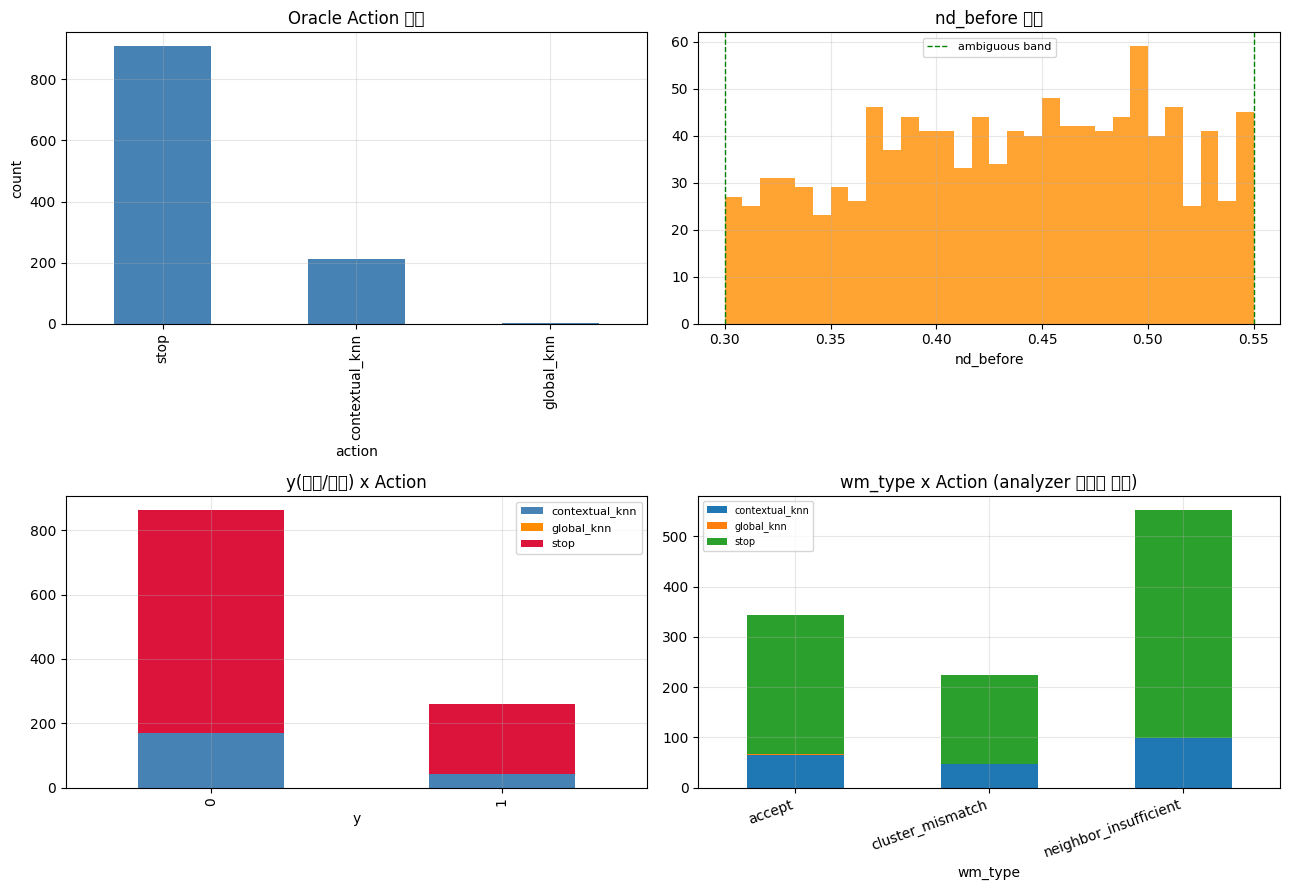

In [150]:
# ============================================================
# Training Data 통계 분석 (evaluator NB2 cell 8과 동일 관점으로 재구성)
# ============================================================
import matplotlib.pyplot as plt

_base = oracle_best.reset_index()
n = len(_base)
bar = "=" * 70

print(bar)
print(f"Planner Oracle 데이터 분석 ({n:,} test_idx, lambda={PLANNER_REWARD_LAMBDA})")
print(bar)

print("\n[GT Label(y) 분포]")
print(f"  NORMAL (y=0):   {(_base['y']==0).sum():4,}개 ({(_base['y']==0).mean()*100:5.1f}%)")
print(f"  ABNORMAL (y=1): {(_base['y']==1).sum():4,}개 ({(_base['y']==1).mean()*100:5.1f}%)")

print("\n[Action(oracle) 분포]")
for act, cnt in _base["action"].value_counts().items():
    print(f"  {act:<16s}: {cnt:4,}개 ({cnt/n*100:5.1f}%)")

print("\n[nd_before 분포] (evaluator의 distance range와 동일 bin)")
_nd = _base["nd_before"]
for name, mask in [("< 0.3 (confident-normal)", _nd < 0.3),
                   ("0.3-0.55 (ambiguous)", (_nd >= 0.3) & (_nd < 0.55)),
                   (">= 0.55 (confident-abnormal)", _nd >= 0.55)]:
    print(f"  {name:32s}: {mask.sum():4,}개 ({mask.mean()*100:5.1f}%)")

print("\n[GT Label x nd_before range 교차분석]")
_base["_nd_band"] = pd.cut(_nd, [0, 0.3, 0.55, 1.0], labels=["<0.3", "0.3-0.55", ">=0.55"])
print(pd.crosstab(_base["_nd_band"], _base["y"], margins=True).to_string())

print("\n[wm_type x action 교차분석] (analyzer가 실제로 호출된 표본만)")
_wm_valid = _base[_base["wm_type"].notna()]
if len(_wm_valid):
    print(pd.crosstab(_wm_valid["wm_type"], _wm_valid["action"]).to_string())

# ── 시각화 (evaluator NB2 스타일 -- 2x2 figure) ──
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

a = ax[0, 0]
_base["action"].value_counts().plot(kind="bar", ax=a, color="steelblue")
a.set_title("Oracle Action 분포"); a.set_ylabel("count"); a.grid(alpha=.3)

a = ax[0, 1]
a.hist(_nd, bins=30, color="darkorange", alpha=.8)
a.axvline(0.3, color="green", ls="--", lw=1, label="ambiguous band")
a.axvline(0.55, color="green", ls="--", lw=1)
a.set_title("nd_before 분포"); a.set_xlabel("nd_before"); a.legend(fontsize=8); a.grid(alpha=.3)

a = ax[1, 0]
pd.crosstab(_base["y"], _base["action"]).plot(kind="bar", stacked=True, ax=a,
                                              color=["steelblue", "darkorange", "crimson"])
a.set_title("y(정상/사기) x Action"); a.set_xlabel("y"); a.legend(fontsize=8); a.grid(alpha=.3)

a = ax[1, 1]
if len(_wm_valid):
    pd.crosstab(_wm_valid["wm_type"], _wm_valid["action"]).plot(kind="bar", stacked=True, ax=a)
    a.set_title("wm_type x Action (analyzer 호출된 표본)"); a.legend(fontsize=7); a.grid(alpha=.3)
    plt.setp(a.get_xticklabels(), rotation=20, ha="right")

plt.tight_layout()
plt.savefig("/content/planner_data_stats.png", dpi=120, bbox_inches="tight")
plt.show()
print(bar)


In [151]:
# ============================================================
# Planner prompt 재구성 -- test_idx별로 오라클 rollout 당시의 원재료
# (test_features/persona/neighbors)를 다시 모아 build_planner_user_prompt()에
# 그대로 넣는다.
# ★ [버그 수정 x2]
#  1) gt_loader.py는 common/*.py 번들(config/prompts/data_io/schema)에 없어서
#     그냥 import하면 ModuleNotFoundError다 -- evaluator 쪽은 teacher가 만든
#     jsonl(agent 모드 학습/평가셋)만 쓰기 때문에 GTLoader 자체가 필요 없었다.
#     여기서는 test_idx -> raw feature 매핑이 필요해서 원본 test parquet을
#     읽어야 하므로, gt_loader.py를 import하지 않고 그 안의 경로 상수만
#     참고해서 이 셀에서 직접 읽는다(요청하신 대로 노트북 로컬 정의).
#  2) GTLoader.load_minimal()은 google.cloud.storage로 재다운로드하는 방식인데,
#     지금 이미 gcsfuse로 버킷 전체가 /content/gcs_mount에 마운트돼 있으니
#     그냥 그 경로에서 pd.read_parquet/np.load로 바로 읽는 게 더 빠르고
#     간단하다(오라클 parquet을 mount 경로에서 직접 읽은 것과 동일 패턴).
#     경로 템플릿은 gt_loader.py의 TEST_PARQUET_PATH_TEMPLATE/TEST_EMBEDDING_PATH
#     상수를 그대로 옮겨온 것 -- gt_loader.py가 바뀌면 여기도 맞춰야 한다.
# ============================================================
from prompts import build_planner_user_prompt, PLANNER_SYSTEM_PROMPT, build_planner_user_prompt_v2

_TEST_PARQUET_PATH = (
    f"/content/gcs_mount/tree-search/tree_fraudecom/"
    f"{ORACLE_EXPERIMENT_CASE}/test_with_gt.parquet"
)
_TEST_EMB_PATH = (
    "/content/gcs_mount/tree-search/embeddings_fraudecom/"
    "anollm_lr5e-05_standard_smolLM_test_embeddings_merged.npy"
)

if "test_data" not in globals():
    test_data = pd.read_parquet(_TEST_PARQUET_PATH)
    print(f"test_data 직접 로드(mount 경로): shape={test_data.shape}")
else:
    print("test_data 이미 존재 -- 재사용")
# test_emb는 이 셀의 prompt 재구성에는 필요 없다(오라클에 이미 neighbors/
# distances가 backfill돼 있음) -- 혹시 다른 셀에서 필요해질 경우를 대비해
# 같은 패턴으로만 남겨둔다.
# test_emb = np.load(_TEST_EMB_PATH)


def _test_features_of(idx: int) -> dict:
    row = test_data.iloc[idx] if hasattr(test_data, "iloc") else test_data[idx]
    cols = ["purchase_value", "age", "sex", "source", "browser",
            "IP_country", "month_purchase", "weekday_purchase"]
    return {c: row[c] for c in cols if c in row}

def build_planner_prompt_for_test_idx(test_idx: int) -> str:
    orow = oracle_best.loc[test_idx]
    tf = _test_features_of(test_idx)
    persona = orow["persona"]
    neighbors = orow["neighbors"] or []
    distances = [n["distance"] for n in neighbors if "distance" in n]
    topk_feats = [n.get("features", {}) for n in neighbors]
    candidate_features = list(dict.fromkeys((orow["agrees"] or []) + (orow["persona_match"] or [])))
    # return build_planner_user_prompt(
    #     test_features=tf, cluster_id=orow["cluster_id"], distances=distances,
    #     persona=persona, topk_feats=topk_feats, candidate_features=candidate_features,
    # )
    return build_planner_user_prompt_v2(
        test_features=tf, cluster_id=orow["cluster_id"], distances=distances,
        persona=persona, topk_feats=topk_feats, candidate_features=candidate_features,
    )


_sample_idx = oracle_best.index[0]
print(build_planner_prompt_for_test_idx(_sample_idx)[:1200])


test_data 이미 존재 -- 재사용
Choose exactly one retrieval action for this transaction, based on the evidence below.

## ACTIONS
  stop            - cost=0
  global_knn      - cost=1.5
  contextual_knn  - cost=1.2, requires "features": up to 2 values from CANDIDATE FEATURES

## CANDIDATE FEATURES (for contextual_knn only)
sex, source, browser

Output ONLY compact JSON, no markdown, no explanation:
{"action":"stop"}
{"action":"global_knn"}
{"action":"contextual_knn","features":["<field1>","<field2 optional>"]}

## TEST
[Numeric Features]
  - age: -0.9

[Categorical Features]
  - sex: M
  - source: Ads
  - browser: Chrome

## CLUSTER FIT (z vs persona)
  - age: value=-0.9, z=-0.84 [ok]

## PERSONA DOMINANCE (categorical)
  - sex: dom=M(0.63) [match]
  - source: dom=Ads(0.55) [match]
  - browser: dom=FireFox(0.69) [RARE]
  - IP_country: dom=United States(0.36) [ok]
  - month_purchase: dom=May(0.15) [ok]
  - weekday_purchase: dom=Tuesday(0.16) [ok]

## RETRIEVAL
nd(top1)=0.34 | neighbor_spread=0.

### [G3/P1 analog] 식별가능성(identifiability) ceiling check
evaluator NB2의 [P0-v2] G3("features={...} majority=... tree/RF CV acc")와 [P1]
(lexical vs numeric feature importance)을 planner 버전으로 재구성했다.
목적은 동일하다 -- **0.5B LLM을 학습시키기 전에, 이 state 표현만으로 oracle
action을 예측하는 게 원리적으로 가능한 문제인지**를 먼저 확인한다. 간단한
tree/RF조차 majority-class(=항상 stop) baseline을 못 이기면, LLM SFT/GRPO도
크게 다르지 않을 가능성이 높다 -- 그 경우 문제는 모델 크기가 아니라 state
표현(agrees/differs/deviant/rare/spread_tag 조합)에 있다는 뜻이다.

In [152]:
# ============================================================
# [G3 analog] 구조화 feature -> oracle_action 식별가능성 (tree/RF CV)
# ============================================================
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import classification_report

def _row_features(row) -> dict:
    d = {
        "n_agrees": len(row["agrees"] or []),
        "n_differs": len(row["differs"] or []),
        "n_deviant": len(row["deviant"] or []),
        "n_rare": len(row["rare"] or []),
        "n_persona_match": len(row["persona_match"] or []),
        "spread": int(row["spread_tag"] == "spread"),
        "nd_before": float(row["nd_before"]),
    }
    for f in prompts.CATEGORICAL_COLS if hasattr(prompts, "CATEGORICAL_COLS") else []:
        d[f"agree__{f}"] = int(f in (row["agrees"] or []))
        d[f"deviant__{f}"] = int(f in (row["deviant"] or []))
        d[f"rare__{f}"] = int(f in (row["rare"] or []))
    return d

_base = oracle_best.reset_index()
X = pd.DataFrame([_row_features(r) for _, r in _base.iterrows()]).fillna(0.0)
y_act = _base["action"].values

print(f"[G3] features={X.shape[1]}  majority={pd.Series(y_act).value_counts(normalize=True).max():.3f}"
      f"  (majority=항상 최빈 action만 찍을 때의 accuracy -- 이걸 못 이기면 학습 무의미)")
for name, clf in [("tree d=3", DecisionTreeClassifier(max_depth=3, random_state=0)),
                  ("tree d=6", DecisionTreeClassifier(max_depth=6, random_state=0)),
                  ("RF-300", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))]:
    acc = cross_val_score(clf, X, y_act, cv=5).mean()
    print(f"  {name:9s} CV acc = {acc:.3f}")

rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X, y_act)
print("\n  top-12 feature importance:")
print(pd.Series(rf.feature_importances_, index=X.columns).nlargest(12).round(4).to_string())

print("\n  (참고) depth-3 규칙:")
print(export_text(DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y_act),
                  feature_names=list(X.columns), decimals=3))

# ── per-class recall (evaluator [P0-v3] ①과 동일) ──
_pred = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=0), X, y_act, cv=5)
print("\n[per-class] tree d=4 CV 예측")
print(classification_report(y_act, _pred, digits=3, zero_division=0))


[G3] features=25  majority=0.811  (majority=항상 최빈 action만 찍을 때의 accuracy -- 이걸 못 이기면 학습 무의미)
  tree d=3  CV acc = 0.808
  tree d=6  CV acc = 0.788


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


  RF-300    CV acc = 0.744

  top-12 feature importance:
nd_before           0.7658
n_persona_match     0.0853
spread              0.0303
n_deviant           0.0232
agree__sex          0.0142
n_differs           0.0128
n_agrees            0.0127
agree__browser      0.0117
agree__source       0.0113
n_rare              0.0106
rare__IP_country    0.0102
rare__source        0.0084

  (참고) depth-3 규칙:
|--- nd_before <= 0.433
|   |--- nd_before <= 0.392
|   |   |--- nd_before <= 0.318
|   |   |   |--- class: stop
|   |   |--- nd_before >  0.318
|   |   |   |--- class: stop
|   |--- nd_before >  0.392
|   |   |--- n_persona_match <= 1.500
|   |   |   |--- class: stop
|   |   |--- n_persona_match >  1.500
|   |   |   |--- class: stop
|--- nd_before >  0.433
|   |--- agree__sex <= 0.500
|   |   |--- rare__source <= 0.500
|   |   |   |--- class: stop
|   |   |--- rare__source >  0.500
|   |   |   |--- class: contextual_knn
|   |--- agree__sex >  0.500
|   |   |--- n_agrees <= 2.500
|   |   |   

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


[LEXICAL only (태그/카운트)]  n_feat=24  acc=0.790
    stop             recall=0.970  precision=0.809
    global_knn       recall=0.000  precision=0.000
    contextual_knn   recall=0.019  precision=0.129


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/tmp/ipykernel_3124/3022067730.py:29: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3022067730.py:29: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3022067730.py:29: UserWarning: Glyph 52852 (\N{HANGUL SYLLABLE KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3022067730.py:29: UserWarning: Glyph 50868 (\N{HANGUL SYLLABLE UN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3022067730.py:29: UserWa

[ALL (+ nd_before)]  n_feat=25  acc=0.796
    stop             recall=0.969  precision=0.814
    global_knn       recall=0.000  precision=0.000
    contextual_knn   recall=0.052  precision=0.282


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52852 (\N{HANGUL SYLLABLE KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50868 (\N{HANGUL SYLLABLE UN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


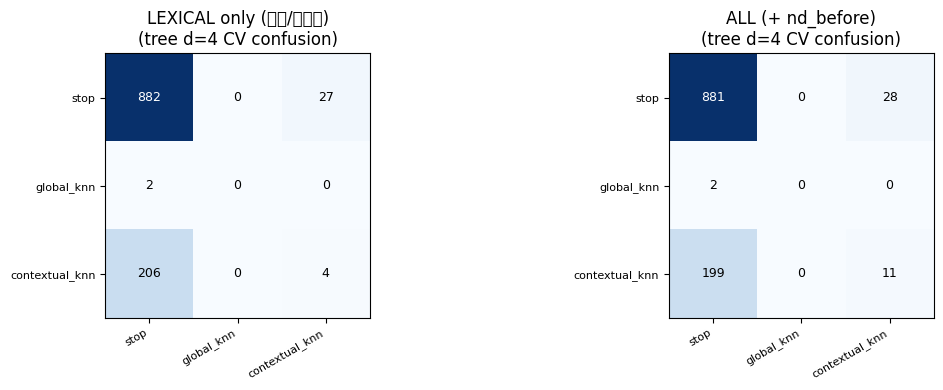

In [153]:
# ============================================================
# [P1 analog] lexical(태그/카운트) vs numeric(nd_before) feature importance
# ============================================================
_lex = [c for c in X.columns if c.startswith(("agree__", "deviant__", "rare__"))] + \
       ["n_agrees", "n_differs", "n_deviant", "n_rare", "n_persona_match", "spread"]
_num = ["nd_before"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, cols) in enumerate([("LEXICAL only (태그/카운트)", _lex), ("ALL (+ nd_before)", list(X.columns))]):
    p = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=0), X[cols], y_act, cv=5)
    rep = classification_report(y_act, p, output_dict=True, zero_division=0)
    print(f"[{name}]  n_feat={len(cols)}  acc={rep['accuracy']:.3f}")
    for k in ("stop", "global_knn", "contextual_knn"):
        if k in rep:
            print(f"    {k:<16s} recall={rep[k]['recall']:.3f}  precision={rep[k]['precision']:.3f}")

    cm = pd.crosstab(pd.Series(y_act, name="actual"), pd.Series(p, name="predicted"))
    cm = cm.reindex(index=["stop", "global_knn", "contextual_knn"],
                    columns=["stop", "global_knn", "contextual_knn"]).fillna(0)
    a = ax[i]
    im = a.imshow(cm.values, cmap="Blues")
    a.set_xticks(range(3)); a.set_xticklabels(cm.columns, rotation=30, ha="right", fontsize=8)
    a.set_yticks(range(3)); a.set_yticklabels(cm.index, fontsize=8)
    for r in range(3):
        for c in range(3):
            a.text(c, r, int(cm.values[r, c]), ha="center", va="center", fontsize=9,
                  color="white" if cm.values[r, c] > cm.values.max()/2 else "black")
    a.set_title(f"{name}\n(tree d=4 CV confusion)")
plt.tight_layout()
plt.savefig("/content/planner_identifiability_confusion.png", dpi=120, bbox_inches="tight")
plt.show()


[균등 샘플링] (oracle_action 기준, majority)
  stop            : 원본   909 -> majority 후   909
  contextual_knn  : 원본   210 -> majority 후   840
  global_knn      : 원본     2 -> majority 후     8

  총 학습 표본: 1757
  train(majority)=1561  eval(자연분포)=112


/tmp/ipykernel_3124/3276983610.py:86: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("/content/planner_balance_before_after.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/3276983610.py:86: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("/content/planner_balance_before_after.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/3276983610.py:86: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("/content/planner_balance_before_after.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/3276983610.py:86: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("/content/planner_balance_before_after.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/3276983610.py:86: UserWarning: Glyph 54980 (\N{H

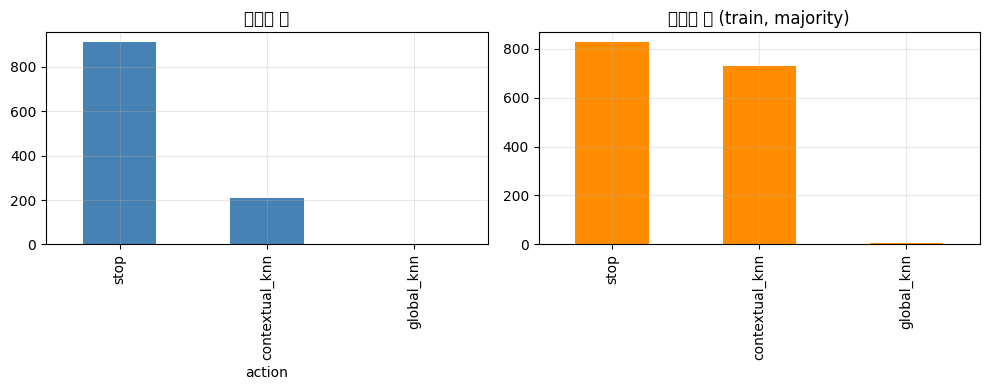

In [154]:
# ============================================================
# 학습 pool 구성 -- oracle_action 기준 4가지 전략 중 선택
#   "downsample" : 소수 클래스 크기에 맞춰 다수 클래스를 줄임 (1:1:1)
#   "majority"   : 다수 클래스(stop)는 그대로 두고, 소수 클래스만 제한된
#                  배수로 늘림 -- 완전 균등(1:1:1)과 원본 불균형(84.5%)의
#                  절충안. 다수 클래스가 여전히 우세하되 소수 클래스 학습
#                  기회도 어느 정도 확보한다.
#   "natural"    : 리샘플링 없음 -- oracle_best의 원본 분포(stop 84.5%) 그대로.
#   "oversample" : (기존 코드 보존, 기본값 아님) 소수 클래스를 다수 클래스
#                  크기에 맞춰 복원추출 -- SFT/GRPO 학습 시간이 너무 길어서
#                  당분간 회피. 코드만 남겨둠.
# ============================================================
import random as _rnd

MAJORITY_OVERSAMPLE_CAP = 4   # "majority" 전략에서 소수 클래스를 최대 몇 배까지 늘릴지

def build_uniform_action_dataset(oracle_best_df: pd.DataFrame, seed: int = 42,
                                 strategy: str = "downsample") -> list:
    _r = _rnd.Random(seed)
    by_action = {}
    for idx, row in oracle_best_df.iterrows():
        by_action.setdefault(row["action"], []).append(idx)

    if strategy == "natural":
        # 리샘플링 없음 -- 원본 분포 그대로 반환 (셔플만)
        balanced = [i for idxs in by_action.values() for i in idxs]
        for act, idxs in by_action.items():
            print(f"  {act:<16s}: 원본 {len(idxs):5d} -> natural(무변경) {len(idxs):5d}")
        _r.shuffle(balanced)
        return balanced

    majority_n = max(len(v) for v in by_action.values())
    minority_n = min(len(v) for v in by_action.values())

    balanced = []
    for act, idxs in by_action.items():
        pool = list(idxs)
        _r.shuffle(pool)

        if strategy == "downsample":
            target_n = minority_n
            sampled = pool[:target_n]

        elif strategy == "majority":
            # 다수 클래스는 그대로, 소수 클래스만 최대 MAJORITY_OVERSAMPLE_CAP배까지
            # (다수 클래스 크기를 넘지는 않게) 복원추출로 늘린다.
            target_n = len(pool) if len(pool) == majority_n else min(majority_n, len(pool) * MAJORITY_OVERSAMPLE_CAP)
            reps = (target_n + len(pool) - 1) // len(pool)
            sampled = (pool * reps)[:target_n]

        elif strategy == "oversample":
            # ── 기존 코드 보존 (기본값 아님, 회피 대상) ──
            target_n = majority_n
            reps = (target_n + len(pool) - 1) // len(pool)
            sampled = (pool * reps)[:target_n]

        else:
            raise ValueError(f"알 수 없는 strategy: {strategy!r} "
                            f"(downsample|majority|natural|oversample 중 하나)")

        balanced += sampled
        print(f"  {act:<16s}: 원본 {len(idxs):5d} -> {strategy} 후 {len(sampled):5d}")

    _r.shuffle(balanced)
    return balanced

STRATEGY = "majority"   # "downsample" | "majority" | "natural" | ("oversample" -- 회피)
print(f"[균등 샘플링] (oracle_action 기준, {STRATEGY})")
balanced_test_idx = build_uniform_action_dataset(oracle_best, strategy=STRATEGY)
print(f"\n  총 학습 표본: {len(balanced_test_idx)}")

_unique_idx = sorted(oracle_best.index.tolist())
_r = _rnd.Random(42); _r.shuffle(_unique_idx)
_n_eval = max(1, int(len(_unique_idx) * 0.1))
eval_test_idx_set = set(_unique_idx[:_n_eval])
train_balanced_idx = [i for i in balanced_test_idx if i not in eval_test_idx_set]
eval_idx = [i for i in _unique_idx if i in eval_test_idx_set]
print(f"  train({STRATEGY})={len(train_balanced_idx)}  eval(자연분포)={len(eval_idx)}")

# ── 시각화: 균등화 전/후 분포 비교 ──
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
_before = oracle_best["action"].value_counts()
_after = pd.Series(oracle_best.loc[train_balanced_idx, "action"].values).value_counts()
_before.plot(kind="bar", ax=ax[0], color="steelblue"); ax[0].set_title("균등화 전"); ax[0].grid(alpha=.3)
_after.plot(kind="bar", ax=ax[1], color="darkorange"); ax[1].set_title(f"균등화 후 (train, {STRATEGY})"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("/content/planner_balance_before_after.png", dpi=120, bbox_inches="tight")
plt.show()

## Section P-11: Config -- SFT/GRPO 템플릿, LoRA, Qwen2.5-0.5B

In [218]:
# ============================================================
# PLANNER_STAGE -- "GRPO가 SFT 대비 의미 있는가"를 먼저 확인하기 위한 스위치.
# evaluator NB2의 EXPERIMENT_STAGE(S1~S5) 패턴과 동일한 dict 구조.
# ============================================================
PLANNER_STAGE = "SFT_THEN_GRPO"     # "SFT_ONLY" | "SFT_THEN_GRPO"
_STAGE_CFG = {
    "SFT_ONLY":       dict(use_grpo=False),
    "SFT_THEN_GRPO":  dict(use_grpo=True),
}[PLANNER_STAGE]
USE_GRPO = _STAGE_CFG["use_grpo"]
print(f"PLANNER_STAGE={PLANNER_STAGE}  USE_GRPO={USE_GRPO}")

BASE_MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

# ★ [신규] 여기서 미리 정의 -- SFT 완료 직후(런타임 연속성용 GCS 업로드)와
# GRPO 시작 시점(GCS에서 SFT adapter 재로드) 둘 다 이 경로를 참조해야 해서
# Section P-12(맨 끝)에 있던 정의를 앞으로 옮겼다.
PLANNER_ADAPTER_GCS_BASE = (
    f"/content/gcs_mount/tree-search/analyzer_ft/{ORACLE_EXPERIMENT_CASE}/planner"
)

GRPO_NUM_GENERATIONS = 6
GRPO_BATCH_SIZE      = 6
GRPO_EPOCHS          = 1
GRPO_MAX_STEPS       = 150
GRPO_LR              = 3e-6
GRPO_KL_COEF         = 0.04     #Default : 0.15
GRPO_TEMPERATURE     = 1.1      #DEFAULT : 1.0
GRPO_MAX_NEW         = 24
GRPO_INVALID_PENALTY = -1.0
GRPO_FORMAT_PENALTY  = -1.5
# GRPO_INVALID_PENALTY = -0.1
# GRPO_FORMAT_PENALTY  = -0.2
scale_rewards = False
# ── [신규] GRPO 전용 prompt 선택 전략 ──
# SFT의 class balance(label 분포)와는 다른 문제: GRPO는 "state 자체"를 얼마나
# 자주 보여줄지가 gradient 배분을 결정한다. oracle이 stop이 아닌 state
# (검색이 실제로 의미 있는 ~15% state)를 자연분포 그대로 두면, "하지 마라"
# 신호(다수 state)에 묻혀서 학습이 안 된다는 게 지난 텔레메트리로 확인됨.
GRPO_PROMPT_FILTER = "natural"   # "natural" | "search_oversample"
GRPO_SEARCH_OVERSAMPLE_RATIO = 3           # non-stop state를 몇 배로 늘릴지

# ── [신규] DAPO 스타일 dynamic sampling + feature-match 부분 점수 ──
GRPO_DYNAMIC_SAMPLING = True    # on/off
# hard cutoff(분산>threshold만 포함) 대신, 분산에 비례한 연속 가중치를 써서
# "완전 제외"가 아니라 "덜 자주 보여주는" smooth한 방식으로 구현.
GRPO_VARIANCE_THRESHOLD  = 0.03   # 이 분산 이상이면 가중치 1.0(풀 반영)
GRPO_VARIANCE_MIN_WEIGHT = 0.0   # 분산 0이어도 완전히 안 보이진 않게(파국적 망각 방지) 최소 가중치
GRPO_VARIANCE_POWER      = 1.0    # 1.0=선형, >1.0이면 threshold 근처까지는 완만하다가 급격히 올라감(더 hard에 가까워짐)
# → 나중에 GRPO_VARIANCE_MIN_WEIGHT를 낮추고 GRPO_VARIANCE_POWER를 올리면
#   smooth(지금 설정) -> hard(원래 제안한 완전 컷오프) 사이를 연속적으로 오갈 수 있음

GRPO_FEATURE_MATCH_BONUS       = True
GRPO_FEATURE_MATCH_BONUS_SCALE = 0.3   # overlap 비율(0~1) * 이 값만큼 INVALID_PENALTY를 완화

GRPO_DYNAMIC_SAMPLING_BASE_REPEATS = 4   # n=1짜리 natural 분포에서도 smooth weighting이 실제로 작동하려면 최소 이 정도는 필요

PLANNER_STAGE=SFT_THEN_GRPO  USE_GRPO=True


In [219]:
# ============================================================
# ChatML SFT 데이터셋 -- 타깃은 oracle argmax(=오라클이 고른 action/features)
# 그대로 behavior cloning. 균등 샘플링(train_balanced_idx)을 그대로 사용.
# ============================================================
from datasets import Dataset

def _target_json_for(test_idx: int) -> str:
    row = oracle_best.loc[test_idx]
    if row["action"] == "contextual_knn":
        feats = row["features"] if isinstance(row["features"], list) else []
        return _json.dumps({"action": "contextual_knn", "features": feats}, ensure_ascii=False)
    return _json.dumps({"action": row["action"]}, ensure_ascii=False)

def to_chatml_planner(test_idx: int) -> dict:
    user = build_planner_prompt_for_test_idx(test_idx)
    asst = _target_json_for(test_idx)
    text = (f"<|im_start|>system\n{PLANNER_SYSTEM_PROMPT}<|im_end|>\n"
            f"<|im_start|>user\n{user}<|im_end|>\n"
            f"<|im_start|>assistant\n{asst}<|im_end|>")
    return {"text": text, "test_idx": test_idx}

train_dataset = Dataset.from_list([to_chatml_planner(i) for i in train_balanced_idx])
eval_dataset  = Dataset.from_list([to_chatml_planner(i) for i in eval_idx])
print(f"Train dataset: {len(train_dataset):,} samples (균등 샘플링, 중복 포함)")
print(f"Eval dataset : {len(eval_dataset):,} samples (자연 분포)")
print("\n[ChatML 샘플 assistant 타깃 분포 -- train]")
_dist = pd.Series([_json.loads(_target_json_for(i))["action"] for i in train_balanced_idx]).value_counts(normalize=True)
print(_dist.apply(lambda x: f"{x:.1%}"))
print("\n[ChatML 샘플 처음 400자]")
print(train_dataset[0]["text"][:400])


Train dataset: 1,561 samples (균등 샘플링, 중복 포함)
Eval dataset : 112 samples (자연 분포)

[ChatML 샘플 assistant 타깃 분포 -- train]
stop              52.9%
contextual_knn    46.6%
global_knn         0.5%
Name: proportion, dtype: object

[ChatML 샘플 처음 400자]
<|im_start|>system
You are a retrieval planner for a fraud-detection agent. Given a transaction's evidence (already retrieved from its assigned cluster), decide whether additional retrieval is worth its cost, and if so, which kind. Re-search is not free — most transactions need no further action.<|im_end|>
<|im_start|>user
Choose exactly one retrieval action for this transaction, based on the evid


In [220]:
# ============================================================
# Student 모델 로드
# ============================================================
import gc, torch
for _var in ["student_model", "student_tokenizer", "model", "tokenizer", "trainer"]:
    if _var in dir():
        exec(f"del {_var}")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

LOCAL_ADAPTER = "/content/planner_adapter"
os.makedirs(LOCAL_ADAPTER, exist_ok=True)

student_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
student_tokenizer.pad_token       = student_tokenizer.eos_token
student_tokenizer.truncation_side = "left"

student_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID, device_map="auto", torch_dtype=torch.bfloat16,
)
print(f"  device: {next(student_model.parameters()).device}")
print(f"  params: {sum(p.numel() for p in student_model.parameters())/1e6:.1f}M")
model, tokenizer = student_model, student_tokenizer


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  device: cuda:0
  params: 494.0M


In [221]:
# ── torchao 0.10.0 (peft 요구 0.16.0+) 버전 충돌 우회 ──
# peft가 torchao를 "미설치"로 인식하게 해 버전 체크를 건너뜀.
# (evaluator NB2 cell 14와 동일한 패치 — Colab 기본 torchao가 peft의
#  최소 요구 버전보다 낮아서 생기는 ImportError를 monkey-patch로 우회한다.
#  torchao를 실제로 업그레이드하는 게 아니라, peft의 버전 체크 함수가
#  참조하는 importlib.metadata.version()이 "0.16.0"이라고 거짓 응답하게
#  만드는 방식이라 재현성 있게 항상 이 패치만 있으면 된다.)
import importlib.metadata as _md
if not getattr(_md, "_torchao_patched", False):
    _orig_v = _md.version
    def _patched_version(n):
        return "0.16.0" if n == "torchao" else _orig_v(n)
    _md.version = _patched_version
    _md._torchao_patched = True
    print("✅ torchao version patch 적용")
else:
    print("⏭️ 이미 패치됨 (재적용 안 함)")

⏭️ 이미 패치됨 (재적용 안 함)


In [222]:
peft_config = LoraConfig(
    r=16, lora_alpha=32,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj"],
    lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir=LOCAL_ADAPTER,
    dataset_text_field="text",
    max_length=1024,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=1,             #default=3
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_steps=15,
    optim="adamw_torch",
    gradient_checkpointing=False,
    save_strategy="epoch",
    eval_strategy="epoch",
    logging_steps=5,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    bf16=True, fp16=False,
    packing=False,
    completion_only_loss=True,
)

trainer = SFTTrainer(
    model=student_model, train_dataset=train_dataset, eval_dataset=eval_dataset,
    args=sft_config, peft_config=peft_config,
)
trainable = sum(p.numel() for p in student_model.parameters() if p.requires_grad)
print(f"  Trainable params: {trainable/1e6:.2f}M")

Adding EOS to train dataset:   0%|          | 0/1561 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1561 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1561 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1561 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1561 [00:00<?, ? examples/s]

...

Tokenizing eval dataset:   0%|          | 0/112 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/112 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/112 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/112 [00:00<?, ? examples/s]

  Trainable params: 2.16M


In [223]:
if PLANNER_STAGE =="SFT_ONLY":
    trainer.train()
    print("SFT 완료")


In [224]:
# ============================================================
# [신규] SFT adapter를 학습 직후 바로 GCS에 업로드 -- 런타임 연속성 보장.
# 이 시점 이후 GRPO 셀은 student_model을 더 이상 신뢰하지 않고, 아래 이
# 경로에서 다시 로드해서 시작한다. 런타임이 SFT와 GRPO 사이에 끊겨도
# (재접속/재시작) GRPO 셀만 다시 실행하면 이어서 진행 가능하다 -- Section
# P-12의 최종 업로드와는 별개로, "SFT 결과부터 우선 안전하게 저장"하는
# 중간 체크포인트다.
# ============================================================
import shutil

def copy_recursive(src_dir: str, dst_dir: str) -> float:
    os.makedirs(dst_dir, exist_ok=True)
    total_kb = 0.0
    for entry in os.scandir(src_dir):
        d = os.path.join(dst_dir, entry.name)
        if entry.is_dir():
            total_kb += copy_recursive(entry.path, d)
        else:
            shutil.copy2(entry.path, d)
            total_kb += os.path.getsize(entry.path) / 1024
    return total_kb

# _best_sft_ckpt = trainer.state.best_model_checkpoint
# if _best_sft_ckpt is None:
#     import glob
#     _ckpt_dirs = sorted(glob.glob(os.path.join(LOCAL_ADAPTER, "checkpoint-*")))
#     _best_sft_ckpt = _ckpt_dirs[-1] if _ckpt_dirs else LOCAL_ADAPTER

# _sft_gcs_path = f"{PLANNER_ADAPTER_GCS_BASE}/planner_adapter_sft"
# _kb = copy_recursive(_best_sft_ckpt, _sft_gcs_path)
# print(f"SFT adapter GCS 저장 완료: {_sft_gcs_path}  ({_kb/1024:.1f} MB)")
# print(f"  (best eval_loss={trainer.state.best_metric}, checkpoint={_best_sft_ckpt})")


### 학습 직후 즉시 점검 (evaluator NB2 cell 22와 동일 목적 -- 학습 곡선 + 생성 sanity check)

/tmp/ipykernel_3124/2249822432.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=.3)


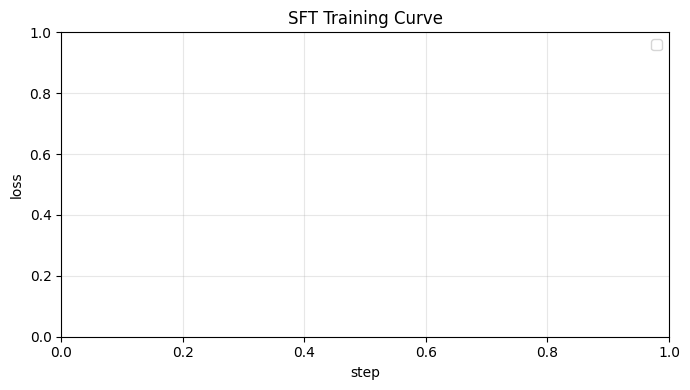

test_idx=2701  oracle_action=stop
모델 생성: '{"action":"stop"}'
JSON 파싱: 성공 -> {'action': 'stop'}


In [225]:
# ============================================================
# [즉시 점검 1] SFT 학습 곡선 (train/eval loss)
# ============================================================
_hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 4))
if "loss" in _hist.columns:
    _tr = _hist.dropna(subset=["loss"])
    ax.plot(_tr["step"], _tr["loss"], label="train loss", color="steelblue", lw=1.5)
if "eval_loss" in _hist.columns:
    _ev = _hist.dropna(subset=["eval_loss"])
    ax.plot(_ev["step"], _ev["eval_loss"], label="eval loss", color="crimson", marker="o")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("SFT Training Curve")
plt.tight_layout(); plt.savefig(f"{LOCAL_ADAPTER}/sft_loss_curve.png", dpi=120, bbox_inches="tight")
plt.show()

# ============================================================
# [즉시 점검 2] 학습 직후 eval 샘플 1개로 바로 생성 테스트
# (evaluator NB2 "cell 66 직후 즉시 1개 생성 테스트"와 동일 목적 --
#  전체 eval 루프 돌리기 전에 출력 형식/붕괴 여부를 빠르게 확인)
# ============================================================
student_model.eval()
_test_ti = eval_idx[0]
_chat = [{"role": "system", "content": PLANNER_SYSTEM_PROMPT},
        {"role": "user", "content": build_planner_prompt_for_test_idx(_test_ti)}]
_inputs = student_tokenizer.apply_chat_template(
    _chat, add_generation_prompt=True, return_tensors="pt", return_dict=True
).to(student_model.device)
with torch.no_grad():
  _out = student_model.generate(
      **_inputs, max_new_tokens=32, do_sample=False,
      pad_token_id=student_tokenizer.eos_token_id,
  )
_gen_text = student_tokenizer.decode(
    _out[0][_inputs["input_ids"].shape[1]:], skip_special_tokens=True
)
print(f"test_idx={_test_ti}  oracle_action={oracle_best.loc[_test_ti, 'action']}")
print(f"모델 생성: {_gen_text!r}")
try:
    _parsed = _json.loads(_gen_text.strip())
    print(f"JSON 파싱: 성공 -> {_parsed}")
except Exception as e:
    print(f"⚠ JSON 파싱 실패: {e}  (형식 붕괴 가능성 -- 아래 전체 eval 전에 프롬프트/completion_only_loss 확인)")


## Section 11-B: GRPO Training (`PLANNER_STAGE == "SFT_THEN_GRPO"`일 때만)

evaluator GRPO(NB2 cell 17)는 reward를 모델이 생성한 텍스트를 정규식으로
채점해서 만들었다(정답이 프롬프트에 없어 grounding을 직접 검증해야 했음).
Planner는 다르다 -- 오라클 rollout이 이미 모든 action의 reward를 전수
계산해뒀다(비판적 검토 §5 "counterfactual exhaustive evaluation"). reward_fn은
모델 출력에서 action(+features)만 파싱해 REWARD_TABLE에서 조회하면 된다.

In [226]:
# ============================================================
# REWARD_TABLE -- ★ [진단 강화] reward_final뿐 아니라 delta_margin/cost도
# 같이 저장 -- "stop으로 쏠리는 게 margin term 때문인지 cost term 때문인지"
# 학습 도중 분해해서 보기 위함.
# ============================================================
from collections import defaultdict

REWARD_TABLE = defaultdict(dict)          # 기존 호환용 -- reward_final만
REWARD_COMPONENTS = defaultdict(dict)     # 신규 -- {"reward","delta_margin","cost"} 전부
for _, row in oracle_df.iterrows():
    key = (row["action"], tuple(sorted(row["features"])) if isinstance(row["features"], list) else ())
    ti = int(row["test_idx"])
    REWARD_TABLE[ti][key] = float(row["reward_final"])
    REWARD_COMPONENTS[ti][key] = {
        "reward": float(row["reward_final"]),
        "delta_margin": float(row["delta_margin"]),
        "cost": float(row["cost"]),
    }

print(f"REWARD_TABLE: {len(REWARD_TABLE)} test_idx, "
      f"평균 {sum(len(v) for v in REWARD_TABLE.values())/len(REWARD_TABLE):.1f} candidate/test_idx")


def _safe_feats_tuple(raw) -> tuple:
    """★ [버그 수정] 모델이 features를 중첩 리스트 등 비정상 형태로 생성해도
    (예: [["source","browser"]]) 항상 hashable한 문자열 튜플로 강제 변환한다.
    안 그러면 tuple 안에 list가 그대로 들어가 dict key 비교(`key in table`)에서
    'unhashable type: list' TypeError가 난다(json.loads 자체는 성공하므로
    기존 try/except로는 못 잡음)."""
    if not isinstance(raw, list):
        return ()
    return tuple(sorted(str(f) for f in raw if isinstance(f, (str, int, float))))

def _feature_match_bonus(feats: tuple, comp_table: dict) -> float:
    """contextual_knn인데 정확히 일치하는 조합이 없을 때, 오라클이 실제로
    시도했던 contextual_knn 후보들과의 최대 Jaccard overlap을 0~1로 반환.
    "완전히 틀림"과 "얼추 비슷한 feature를 골랐음"을 구분하는 신호."""
    candidates = [k[1] for k in comp_table if k[0] == "contextual_knn" and k[1]]
    if not candidates or not feats:
        return 0.0
    best = 0.0
    for cand in candidates:
        inter = len(set(feats) & set(cand))
        union = len(set(feats) | set(cand))
        if union:
            best = max(best, inter / union)
    return best
# ============================================================
# ★ [진단 강화] GRPO_TELEMETRY -- 매 step(=이 함수 1회 호출)마다:
#   - group_diversity: 같은 test_idx(그룹) 안에서 서로 다른 action이
#     몇 종류 나왔는지 평균 (1.0 = 완전 확신/collapse, num_generations에
#     가까울수록 다양함) -- "그룹 내 prompt에 너무 확신 찬 상태인지"의
#     직접적인 실시간 지표.
#   - mean_delta_margin / mean_cost: reward의 두 성분을 분리 기록 --
#     stop 쏠림이 margin term 때문인지 cost term 때문인지 사후 분해.
#   - 매 GRPO_TELEMETRY_PRINT_EVERY번째 step마다 그룹 하나의 실제 생성
#     텍스트 원본을 출력 -- 정말 몇 개 안 되는 답으로 뭉치는지 눈으로 확인.
# ============================================================
GRPO_TELEMETRY = {"step": [], "mean_reward": [], "mean_delta_margin": [],
                  "mean_cost": [], "group_diversity": [],
                  "pred_stop_rate": [], "pred_global_rate": [], "pred_ctx_rate": [],
                  "garbage_rate": [], "valid_group_diversity": []}   # ★ 신규
GRPO_TELEMETRY_PRINT_EVERY = 10
_grpo_step_counter = {"n": 0}


def planner_reward_fn(prompts, completions, test_idx=None, **kwargs):
    rewards = []
    margins, costs = [], []
    parsed_actions = []   # (test_idx, action) -- 그룹 다양성 계산용

    for i, comp in enumerate(completions):
        ti = int(test_idx[i]) if test_idx is not None else None
        text = comp[0]["content"] if isinstance(comp, list) else comp
        try:
            d = _json.loads(text.strip())
            raw_action = d.get("action")
            action = raw_action if isinstance(raw_action, str) else None
            feats = _safe_feats_tuple(d.get("features", [])) if action == "contextual_knn" else ()
            if action is None:
                raise ValueError("action not a string")
        except Exception:
            rewards.append(GRPO_FORMAT_PENALTY)
            parsed_actions.append((ti, "(invalid)"))
            continue

        comp_table = REWARD_COMPONENTS.get(ti, {})
        key = (action, feats)
        if key in comp_table:
            c = comp_table[key]
            rewards.append(c["reward"]); margins.append(c["delta_margin"]); costs.append(c["cost"])
        # elif action == "contextual_knn" and any(k[0] == "contextual_knn" for k in comp_table):
        #     rewards.append(GRPO_INVALID_PENALTY)
        elif action == "contextual_knn" and any(k[0] == "contextual_knn" for k in comp_table):
            base = GRPO_INVALID_PENALTY
            if GRPO_FEATURE_MATCH_BONUS:
                bonus = _feature_match_bonus(feats, comp_table) * GRPO_FEATURE_MATCH_BONUS_SCALE
                rewards.append(base + bonus)
            else:
                rewards.append(base)
        else:
            rewards.append(GRPO_INVALID_PENALTY)
        parsed_actions.append((ti, action))
        # ★ 신규: JSON은 파싱됐지만 action이 3종 밖이면 "garbage"로 별도 표시
        if action not in ("stop", "global_knn", "contextual_knn"):
            parsed_actions[-1] = (ti, "(garbage)")


    # ── 그룹 다양성: 같은 test_idx끼리 묶어서 unique action 개수의 평균 ──
    _by_ti = defaultdict(set)
    for ti, act in parsed_actions:
        _by_ti[ti].add(act)
    group_diversity = float(np.mean([len(v) for v in _by_ti.values()])) if _by_ti else 0.0

    # ★ 신규: garbage/invalid 비율과, 그걸 뺀 "진짜 3-action만의" 다양성
    _all_labels = [a for _, a in parsed_actions]
    garbage_rate = sum(1 for a in _all_labels if a in ("(invalid)", "(garbage)")) / max(len(_all_labels), 1)
    _valid_by_ti = defaultdict(set)
    for ti, act in parsed_actions:
        if act in ("stop", "global_knn", "contextual_knn"):
            _valid_by_ti[ti].add(act)
    valid_group_diversity = float(np.mean([len(v) for v in _valid_by_ti.values()])) if _valid_by_ti else 0.0

    GRPO_TELEMETRY["garbage_rate"].append(garbage_rate)
    GRPO_TELEMETRY["valid_group_diversity"].append(valid_group_diversity)

    _grpo_step_counter["n"] += 1
    GRPO_TELEMETRY["step"].append(_grpo_step_counter["n"])
    GRPO_TELEMETRY["mean_reward"].append(float(np.mean(rewards)) if rewards else 0.0)
    GRPO_TELEMETRY["mean_delta_margin"].append(float(np.mean(margins)) if margins else 0.0)
    GRPO_TELEMETRY["mean_cost"].append(float(np.mean(costs)) if costs else 0.0)
    GRPO_TELEMETRY["group_diversity"].append(group_diversity)

    # ★ [신규] step 전체(6~36개 생성)에서 예측된 action 분포 -- "이번 step에서
    # 모델이 실제로 얼마나 stop에 쏠려 있었는지"를 시간에 따라 직접 봄
    _valid_actions = [a for _, a in parsed_actions if a != "(invalid)"]
    _n_valid = max(len(_valid_actions), 1)
    GRPO_TELEMETRY["pred_stop_rate"].append(_valid_actions.count("stop") / _n_valid)
    GRPO_TELEMETRY["pred_global_rate"].append(_valid_actions.count("global_knn") / _n_valid)
    GRPO_TELEMETRY["pred_ctx_rate"].append(_valid_actions.count("contextual_knn") / _n_valid)

    if _grpo_step_counter["n"] % GRPO_TELEMETRY_PRINT_EVERY == 0:
        _sample_ti = parsed_actions[0][0]
        _sample_texts = [comp[0]["content"] if isinstance(comp, list) else comp
                        for i, comp in enumerate(completions) if test_idx and int(test_idx[i]) == _sample_ti]
        print(f"\n[telemetry step {_grpo_step_counter['n']}] group_diversity={group_diversity:.2f}  "
              f"test_idx={_sample_ti} 그룹 원본 생성 {len(_sample_texts)}개:")
        for t in _sample_texts[:6]:
            print(f"    {t!r}")

    return rewards

print("planner_reward_fn 준비 완료 (오라클 lookup 기반, grounding 채점기 불필요)")


REWARD_TABLE: 2830 test_idx, 평균 3.9 candidate/test_idx
planner_reward_fn 준비 완료 (오라클 lookup 기반, grounding 채점기 불필요)


In [227]:
# ============================================================
# GRPO 학습 데이터셋 -- ★ [신규] GRPO_PROMPT_FILTER="search_oversample"이면
# SFT와 다른 index 소스를 쓴다: train_balanced_idx(SFT의 label-balance 결과)가
# 아니라 oracle_best(eval 제외 전체)에서, oracle_action != "stop"인 state를
# GRPO_SEARCH_OVERSAMPLE_RATIO배 반복해서 섞는다. stop state는 자연 비율
# 그대로 둔다 -- "state를 얼마나 자주 보여줄지"만 조절하는 것이라 SFT의
# label-balance 목적(class-balanced loss)과는 별개 문제.
# ============================================================
def build_grpo_prompt_indices(oracle_best_df: pd.DataFrame, eval_idx_set: set,
                              strategy: str = "search_oversample",
                              oversample_ratio: int = 3, seed: int = 42) -> list:
    _r = _rnd.Random(seed)
    pool = [i for i in oracle_best_df.index if i not in eval_idx_set]
    if strategy == "natural":
        _r.shuffle(pool)
        return pool
    stop_idx = [i for i in pool if oracle_best_df.loc[i, "action"] == "stop"]
    search_idx = [i for i in pool if oracle_best_df.loc[i, "action"] != "stop"]
    grpo_idx = stop_idx + search_idx * oversample_ratio
    _r.shuffle(grpo_idx)
    print(f"  GRPO prompt 구성 (strategy={strategy}): "
          f"stop {len(stop_idx)} + non-stop {len(search_idx)}x{oversample_ratio}"
          f"={len(search_idx)*oversample_ratio}  = 총 {len(grpo_idx)}")
    return grpo_idx


def to_grpo_prompt(test_idx: int) -> dict:
    user = build_planner_prompt_for_test_idx(test_idx)
    return {
        "prompt": [
            {"role": "system", "content": PLANNER_SYSTEM_PROMPT},
            {"role": "user", "content": user},
        ],
        "test_idx": test_idx,
    }

# ============================================================
# [신규] DAPO 스타일 dynamic sampling -- 그룹 reward 분산이 낮은(=거의
# 항상 stop이 압도적으로 이기는) state를 "완전 제거"가 아니라 "덜 자주
# 보여주는" 연속 가중치로 반영한다. DAPO 논문의 발견(분산 0인 그룹은
# advantage가 0이라 gradient에 기여 못 함)을 hard cutoff 대신 smooth하게
# 적용 -- threshold 경계에서 뚝 끊기지 않고, MIN_WEIGHT~1.0 사이를 연속적으로.
# ============================================================
def _reward_variance(ti: int) -> float:
    vals = [c["reward"] for c in REWARD_COMPONENTS.get(ti, {}).values()]
    return float(np.std(vals)) if len(vals) > 1 else 0.0


def apply_dynamic_sampling(indices: list, seed: int = 42) -> list:
    _r = _rnd.Random(seed)
    from collections import Counter
    counts = Counter(indices)
    variances = {ti: _reward_variance(ti) for ti in counts}

    _var_values = np.array(list(variances.values()))
    dynamic_threshold = np.quantile(_var_values, 0.60)
    print(f"  [dynamic sampling] threshold 자동 조정: {GRPO_VARIANCE_THRESHOLD} -> {dynamic_threshold:.4f} (60th pct)")

    weights = {
        ti: GRPO_VARIANCE_MIN_WEIGHT + (1 - GRPO_VARIANCE_MIN_WEIGHT) *
            min(1.0, (variances[ti] / max(dynamic_threshold, 1e-6)) ** GRPO_VARIANCE_POWER)
        for ti in counts
    }

    # ★ [수정] BASE_REPEATS를 전체에 곧이곧대로 곱하지 않고, 평균 가중치가
    # 1이 되도록 재정규화한다 -- 이래야 "전체 크기가 통째로 부풀지 않으면서,
    # 고분산 state는 상대적으로 더 자주, 저분산 state는 덜 자주" 나오는
    # 원래 의도(차등)가 지켜진다. 총 데이터셋 크기는 원본(natural)과 비슷하게
    # 유지된다.
    mean_w = np.mean(list(weights.values())) or 1.0
    scale = GRPO_DYNAMIC_SAMPLING_BASE_REPEATS / (GRPO_DYNAMIC_SAMPLING_BASE_REPEATS * mean_w) \
        if mean_w > 0 else 1.0  # = 1/mean_w, BASE_REPEATS는 최댓값 캡 용도로만 남김

    out = []
    for ti, n in counts.items():
        new_n = max(0, round(n * weights[ti] / mean_w))
        out += [ti] * new_n
    _r.shuffle(out)
    return out


grpo_prompt_indices = build_grpo_prompt_indices(
    oracle_best, set(eval_idx), strategy=GRPO_PROMPT_FILTER,
    oversample_ratio=GRPO_SEARCH_OVERSAMPLE_RATIO,
)
if GRPO_DYNAMIC_SAMPLING:
    _n_before = len(grpo_prompt_indices)
    grpo_prompt_indices = apply_dynamic_sampling(grpo_prompt_indices)
    _var_dist = pd.Series([_reward_variance(i) for i in set(grpo_prompt_indices)])
    print(f"[dynamic sampling] {_n_before} -> {len(grpo_prompt_indices)}  "
          f"(분산 분포: median={_var_dist.median():.4f}, "
          f"분산>{GRPO_VARIANCE_THRESHOLD} 비율={(_var_dist > GRPO_VARIANCE_THRESHOLD).mean():.1%})")

grpo_train_dataset = Dataset.from_list([to_grpo_prompt(i) for i in grpo_prompt_indices])
print(f"GRPO prompt dataset: {len(grpo_train_dataset):,}")

  [dynamic sampling] threshold 자동 조정: 0.03 -> 0.0262 (60th pct)
[dynamic sampling] 1009 -> 952  (분산 분포: median=0.0262, 분산>0.03 비율=27.8%)
GRPO prompt dataset: 952


In [228]:
# ============================================================
# GRPO 학습 실행 -- TRL GRPOTrainer.
# ★ [수정] student_model을 그대로 이어 쓰지 않고, 방금(또는 이전 세션에서)
# GCS에 업로드된 SFT adapter를 새로 로드해서 시작한다 -- 런타임이 SFT와
# GRPO 사이에 끊겨도(재접속/재시작) 이 셀만 다시 실행하면 이어서 GRPO를
# 돌릴 수 있다. (전제: 바로 위 "SFT adapter 즉시 GCS 업로드" 셀 또는 이전
# 세션의 Section P-12 업로드가 먼저 끝나 있어야 한다.)
# ============================================================
if PLANNER_STAGE == "SFT_THEN_GRPO":
    from trl import GRPOConfig, GRPOTrainer
    from peft import PeftModel

    _sft_gcs_path = f"{PLANNER_ADAPTER_GCS_BASE}/planner_adapter_sft"
    assert os.path.isdir(_sft_gcs_path), (
        f"{_sft_gcs_path} 가 없습니다 -- SFT 직후 업로드 셀을 먼저 실행하세요.")

    _grpo_base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_ID, device_map="auto", torch_dtype=torch.bfloat16,
    )
    grpo_model = PeftModel.from_pretrained(_grpo_base, _sft_gcs_path, is_trainable=True)
    print(f"SFT adapter 재로드: {_sft_gcs_path}")

    grpo_config = GRPOConfig(
        output_dir=f"{LOCAL_ADAPTER}_grpo",
        per_device_train_batch_size=GRPO_BATCH_SIZE,
        num_generations=GRPO_NUM_GENERATIONS,
        max_completion_length=GRPO_MAX_NEW,
        num_train_epochs=GRPO_EPOCHS,
        max_steps=GRPO_MAX_STEPS,
        learning_rate=GRPO_LR,
        beta=GRPO_KL_COEF,
        temperature=GRPO_TEMPERATURE,
        logging_steps=5,
        report_to="none",
        bf16=True,
        remove_unused_columns=False,
        scale_rewards=scale_rewards,
    )

    grpo_trainer = GRPOTrainer(
        model=grpo_model,
        args=grpo_config,
        train_dataset=grpo_train_dataset,
        reward_funcs=planner_reward_fn,
        processing_class=student_tokenizer,
    )
    grpo_trainer.train()
    print("GRPO 완료")
else:
    print(f"PLANNER_STAGE={PLANNER_STAGE} -- GRPO 스킵 (SFT_ONLY baseline 단계)")


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.


SFT adapter 재로드: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/planner/planner_adapter_sft


Step,Training Loss
5,0.013232
10,0.029400
15,0.065710
20,0.000544
25,0.002768
30,0.054621
35,0.042277
40,0.038262
45,0.008900
50,0.002719



[telemetry step 10] group_diversity=2.00  test_idx=2455 그룹 원본 생성 6개:
    '{"action": "stop"}'
    '{"action": "contextual_knn", "features": ["source", "browser"]}'
    '{"action": "contextual_knn", "visited_features": ["source"]}'
    '{"action": "contextual_knn", "features": ["source"]}'
    '{"action": "stop"}'
    '{"action": "stop"}'

[telemetry step 20] group_diversity=1.00  test_idx=296 그룹 원본 생성 6개:
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "stop"}'

[telemetry step 30] group_diversity=3.00  test_idx=2182 그룹 원본 생성 6개:
    '{"action": "contextual_knn", "features": ["source"]}'
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "contextual_knn", "features": require("sex", "source")}'
    '{"action": "stop"}'

[telemetry step 40] group_diversity=2.00  test_idx=557 그룹 원본 생성 6개:
    '{"action": "stop"}'
    '{"action": "stop"}'
    '{"action": "st

In [229]:
# print(f"GRPO 실제 로깅된 step 수: {len(grpo_trainer.state.log_history)}")
# print(pd.DataFrame(grpo_trainer.state.log_history)[["step", "loss", "reward", "kl"]].dropna(how="all", subset=["loss","reward","kl"]))

/tmp/ipykernel_3124/1643050425.py:21: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1643050425.py:21: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/1643050425.py:22: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{LOCAL_ADAPTER}_grpo/grpo_curve.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/1643050425.py:22: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{LOCAL_ADAPTER}_grpo/grpo_curve.png", dpi=120, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48708 (\N{

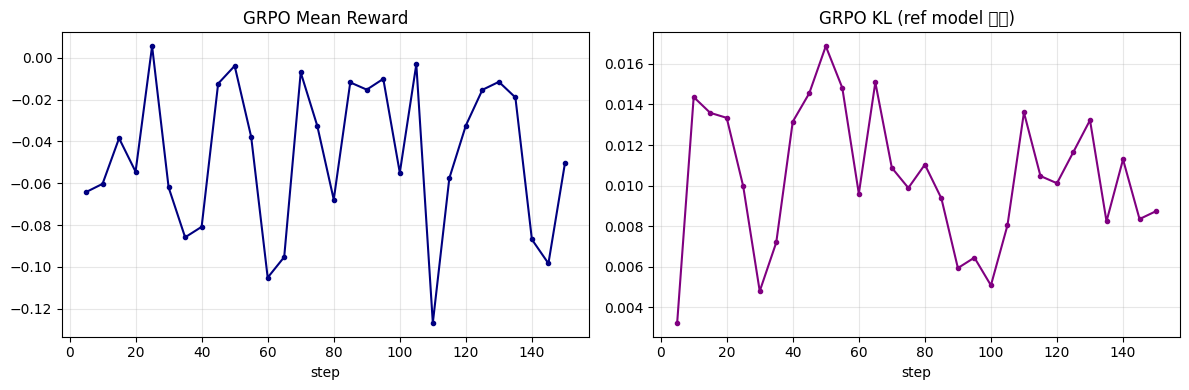

In [230]:
# ============================================================
# [신규] GRPO 학습 곡선 (TRL log_history 기반 -- evaluator NB2 Fig1의
# "Total Reward" 패널과 같은 목적. 커스텀 telemetry 없이 TRL 내장 로그만 사용)
# ============================================================
if PLANNER_STAGE == "SFT_THEN_GRPO":
    _ghist = pd.DataFrame(grpo_trainer.state.log_history)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    a = ax[0]
    if "reward" in _ghist.columns:
        _r = _ghist.dropna(subset=["reward"])
        a.plot(_r["step"], _r["reward"], color="navy", lw=1.5, marker=".")
        a.set_title("GRPO Mean Reward"); a.set_xlabel("step"); a.grid(alpha=.3)

    a = ax[1]
    if "kl" in _ghist.columns:
        _k = _ghist.dropna(subset=["kl"])
        a.plot(_k["step"], _k["kl"], color="purple", lw=1.5, marker=".")
        a.set_title("GRPO KL (ref model 대비)"); a.set_xlabel("step"); a.grid(alpha=.3)

    plt.tight_layout()
    plt.savefig(f"{LOCAL_ADAPTER}_grpo/grpo_curve.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("PLANNER_STAGE=SFT_ONLY -- GRPO 곡선 없음")


/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 54644 (\N{HANGUL SYLLABLE HAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 47353 (\N{HANGUL SYLLABLE RUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 45236 (\N{HANGUL SYLLABLE NAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/3774707125.py:48: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans.
  plt.tight_

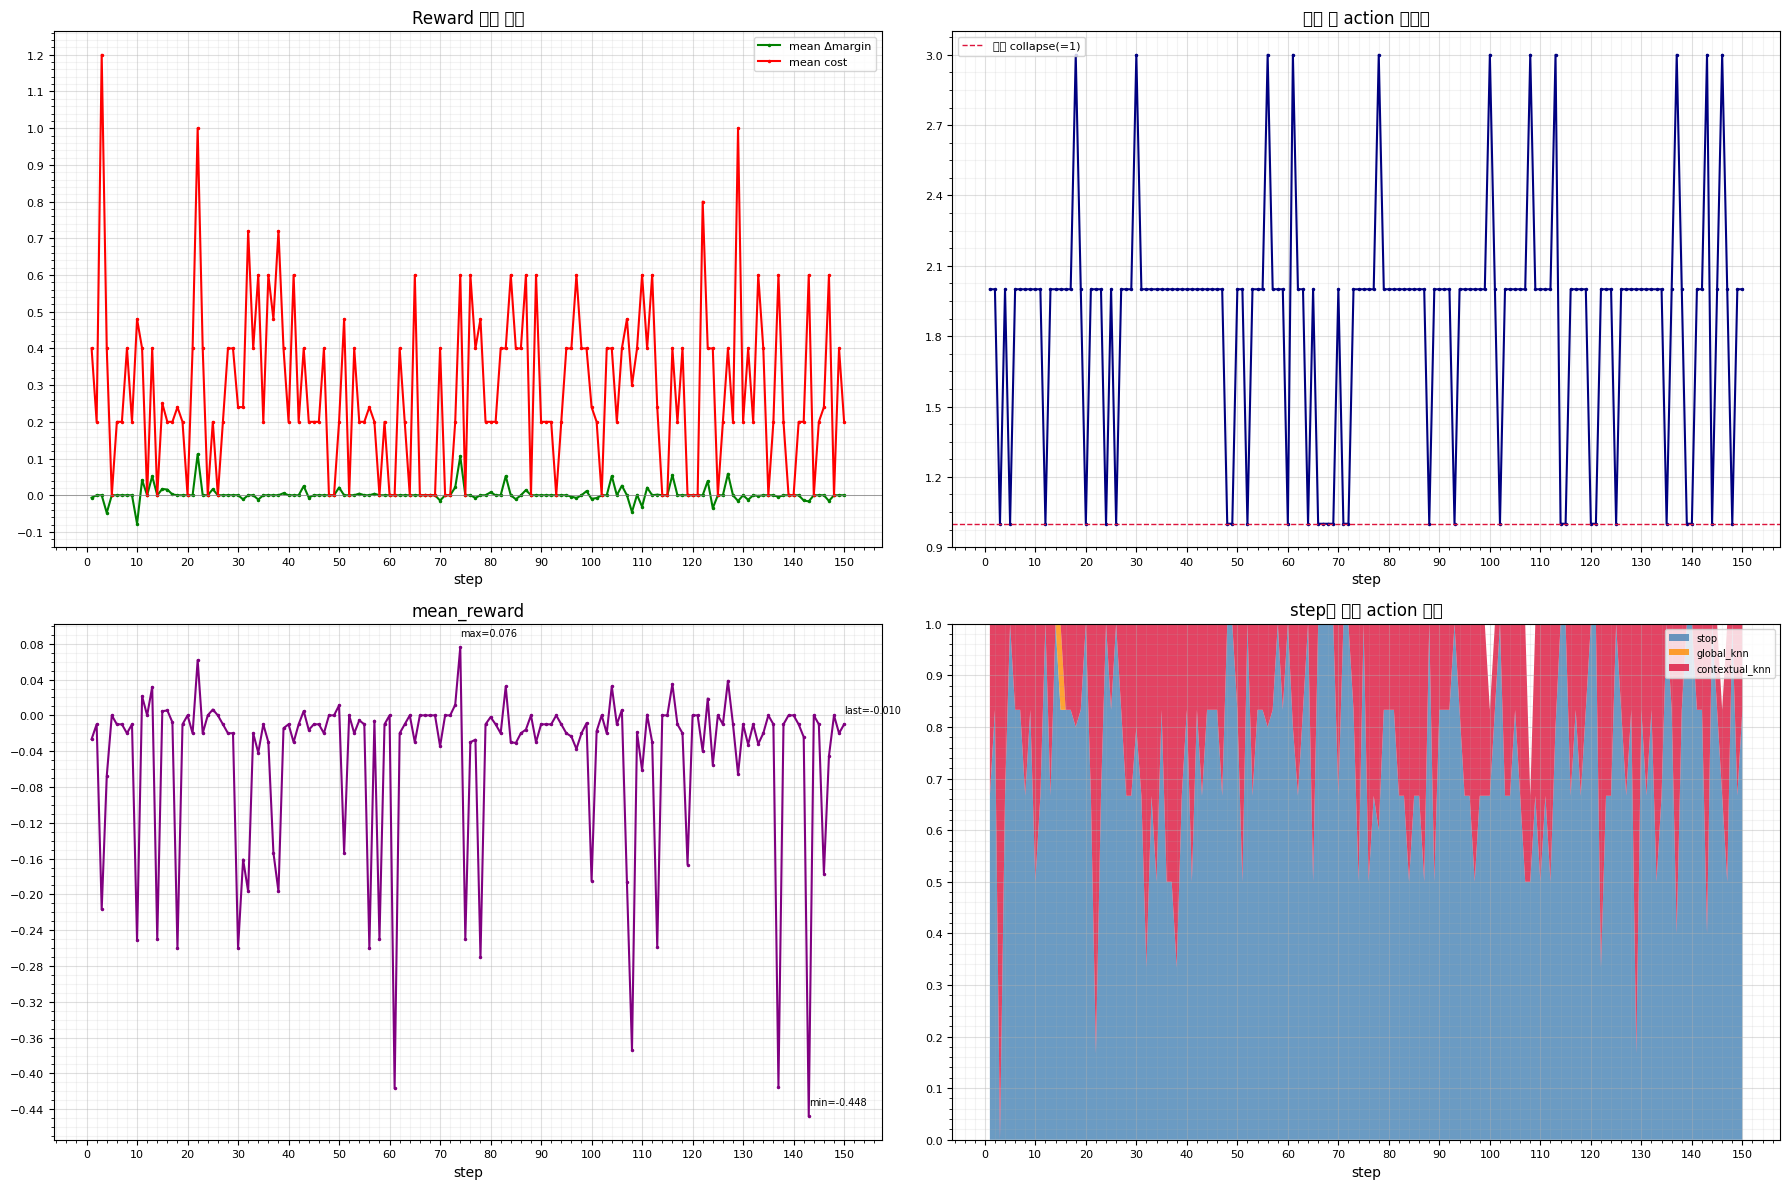


[최근 10 step 원본 수치]
 step  mean_reward  mean_delta_margin  mean_cost  group_diversity  pred_stop_rate  pred_global_rate  pred_ctx_rate  garbage_rate  valid_group_diversity
  141    -0.010033          -0.000033       0.20              2.0        0.833333               0.0       0.166667      0.000000                    2.0
  142    -0.024150          -0.014150       0.20              2.0        0.833333               0.0       0.166667      0.000000                    2.0
  143    -0.447850          -0.016775       0.60              3.0        0.400000               0.0       0.600000      0.166667                    2.0
  144     0.000000           0.000000       0.00              1.0        1.000000               0.0       0.000000      0.000000                    1.0
  145    -0.010000           0.000000       0.20              2.0        0.833333               0.0       0.166667      0.000000                    2.0
  146    -0.176667           0.000000       0.24              3.0   

In [231]:
# ============================================================
# [수정] GRPO_TELEMETRY 시각화 -- 눈금 밀도 강화 + 주요 지점 수치 주석 +
# 원본 수치 표 출력(그래프 해상도와 무관하게 항상 정확한 값 확인 가능)
# ============================================================
from matplotlib.ticker import MaxNLocator

if PLANNER_STAGE == "SFT_THEN_GRPO" and GRPO_TELEMETRY["step"]:
    fig, ax = plt.subplots(2, 2, figsize=(18, 12))   # 32x32는 과했음 -- 정보량 대비 의미 없이 큼

    def _dense_grid(a, ynbins=15, xnbins=20):
        a.xaxis.set_major_locator(MaxNLocator(nbins=xnbins))
        a.yaxis.set_major_locator(MaxNLocator(nbins=ynbins))
        a.grid(which="major", alpha=.4)
        a.grid(which="minor", alpha=.15)
        a.minorticks_on()
        a.tick_params(axis="both", labelsize=8)

    a = ax[0, 0]
    a.plot(GRPO_TELEMETRY["step"], GRPO_TELEMETRY["mean_delta_margin"], label="mean Δmargin", color="green", marker=".", ms=3)
    a.plot(GRPO_TELEMETRY["step"], GRPO_TELEMETRY["mean_cost"], label="mean cost", color="red", marker=".", ms=3)
    a.axhline(0, color="gray", lw=0.5)
    a.set_title("Reward 성분 분해"); a.set_xlabel("step"); a.legend(fontsize=8); _dense_grid(a)

    a = ax[0, 1]
    a.plot(GRPO_TELEMETRY["step"], GRPO_TELEMETRY["group_diversity"], color="navy", marker=".", ms=3)
    a.axhline(1.0, color="crimson", ls="--", lw=1, label="완전 collapse(=1)")
    a.set_title("그룹 내 action 다양성"); a.set_xlabel("step"); a.legend(fontsize=8); _dense_grid(a, ynbins=8)

    a = ax[1, 0]
    a.plot(GRPO_TELEMETRY["step"], GRPO_TELEMETRY["mean_reward"], color="purple", marker=".", ms=3)
    # ★ 최고/최저/마지막 값 주석 -- 그림만 봐도 핵심 수치가 바로 보이게
    _r = GRPO_TELEMETRY["mean_reward"]; _s = GRPO_TELEMETRY["step"]
    _imax, _imin = int(np.argmax(_r)), int(np.argmin(_r))
    for _i, _lbl in [(_imax, "max"), (_imin, "min"), (len(_r)-1, "last")]:
        a.annotate(f"{_lbl}={_r[_i]:.3f}", (_s[_i], _r[_i]), fontsize=7,
                   textcoords="offset points", xytext=(0, 8))
    a.set_title("mean_reward"); a.set_xlabel("step"); _dense_grid(a)

    a = ax[1, 1]
    a.stackplot(GRPO_TELEMETRY["step"],
               GRPO_TELEMETRY["pred_stop_rate"], GRPO_TELEMETRY["pred_global_rate"],
               GRPO_TELEMETRY["pred_ctx_rate"],
               labels=["stop", "global_knn", "contextual_knn"],
               colors=["steelblue", "darkorange", "crimson"], alpha=.8)
    a.set_title("step별 예측 action 비율"); a.set_xlabel("step")
    a.legend(fontsize=7, loc="upper right"); a.set_ylim(0, 1); _dense_grid(a, ynbins=10)

    plt.tight_layout()
    plt.savefig(f"{LOCAL_ADAPTER}_grpo/grpo_telemetry.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ★ [신규] 그래프와 별개로, 마지막 10개 step의 정확한 수치를 표로도 출력
    print("\n[최근 10 step 원본 수치]")
    print(pd.DataFrame(GRPO_TELEMETRY).tail(10).to_string(index=False))

### SFT vs GRPO 비교 -- "GRPO가 의미 있는가"의 직접적인 답

`PLANNER_STAGE="SFT_ONLY"`로 먼저 돌려 eval_dataset(자연 분포)에서 SFT 모델이
고른 action의 평균 reward를 측정해두고, `PLANNER_STAGE="SFT_THEN_GRPO"`로 다시
돌려 같은 eval_dataset에서 같은 지표를 비교한다. GRPO가 SFT 대비 eval reward를
유의하게 못 올리면 "이 planner task는 RL보다 supervised policy learning으로
충분했다"는 PDF §13의 결론을 따르면 된다.

[SFT_THEN_GRPO] eval mean_reward = 0.0000  (n=112, invalid_format_rate=0.0%)
  참고 baseline (항상 stop): 0.0000
  [non-stop 전용] n=28  mean_reward=0.0000  정답률=0/28 (0.0%)
  참고 baseline (항상 stop): 0.0000


/tmp/ipykernel_3124/100875548.py:86: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/100875548.py:86: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/100875548.py:86: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/100875548.py:86: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3124/100875548.py:87: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{LOCAL_ADAPTER}/eval_confusion_{PLANNER_STAGE.lower()}.png", dpi=120, bbox_inches="tight")
/tmp/ipykernel_3124/100875548.py:87: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{LOCAL_ADAPTER}/eval_confusion_{PLANNER_STAGE.lower()}.png", dp

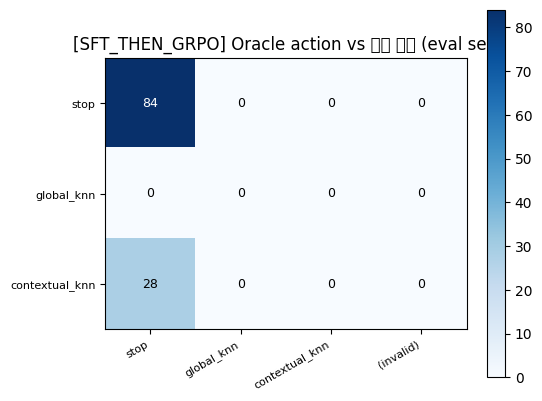

In [217]:
# ============================================================
# Eval: 학습된 모델이 고른 action의 평균 reward + confusion matrix
# ★ [버그 수정] 함수 내부가 자기 지역변수(chat/inputs/model/tokenizer)가
# 아니라 바깥 전역변수(_chat/_inputs/student_model/student_tokenizer -- 직전
# "즉시 점검" 셀에서 test_idx 1개로 만든 값)를 그대로 읽고 있었다 -- 그래서
# eval_test_idx를 몇 개를 순회하든 매번 같은 캐시된 출력만 반환하는 치명적
# 버그였다. 함수 인자로 받은 이름을 정확히 쓰도록 고쳤다.
# ★ [수정] PLANNER_STAGE에 따라 평가 대상 모델을 고른다 -- SFT_THEN_GRPO면
# GRPO로 이어 학습한 grpo_model, SFT_ONLY면 student_model.
# ============================================================
@torch.no_grad()
def evaluate_planner(model, tokenizer, eval_test_idx: list, max_new_tokens=GRPO_MAX_NEW) -> dict:
    model.eval()
    rewards, invalid, preds, golds = [], 0, [], []
    for ti in eval_test_idx:
        user = build_planner_prompt_for_test_idx(ti)
        chat = [{"role": "system", "content": PLANNER_SYSTEM_PROMPT},
                {"role": "user", "content": user}]
        inputs = tokenizer.apply_chat_template(
            chat, add_generation_prompt=True, return_tensors="pt", return_dict=True
        ).to(model.device)
        out = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
        text = tokenizer.decode(
            out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
        )
        golds.append(oracle_best.loc[ti, "action"])
        try:
            d = _json.loads(text.strip())
            action = d.get("action")
            feats = _safe_feats_tuple(d.get("features", [])) if action == "contextual_knn" else ()
        except Exception:
            invalid += 1
            rewards.append(GRPO_FORMAT_PENALTY)
            preds.append("(invalid)")
            continue
        preds.append(action)
        table = REWARD_TABLE.get(ti, {})
        rewards.append(table.get((action, feats), GRPO_INVALID_PENALTY))
    return {"mean_reward": float(np.mean(rewards)), "n": len(rewards),
            "invalid_format_rate": invalid / max(len(eval_test_idx), 1),
            "preds": preds, "golds": golds,
            "rewards": rewards}   # ★ 신규 -- non-stop 전용 지표 재계산용

_eval_model = grpo_model if PLANNER_STAGE == "SFT_THEN_GRPO" else student_model
_result = evaluate_planner(_eval_model, student_tokenizer, eval_idx)
print(f"[{PLANNER_STAGE}] eval mean_reward = {_result['mean_reward']:.4f}  "
      f"(n={_result['n']}, invalid_format_rate={_result['invalid_format_rate']:.1%})")
_stop_baseline = np.mean([REWARD_TABLE[ti].get(("stop", ()), 0.0) for ti in eval_idx])
print(f"  참고 baseline (항상 stop): {_stop_baseline:.4f}")

# ★ [신규] non-stop 전용 지표 -- "stop을 찍으면 오답이어도 reward=0"이라
# 생기는 착시(전체 평균이 0 근처로 보이는 것)를 피하려면, oracle이 stop이
# 아닌 케이스만 따로 떼어봐야 한다. 여기서 나쁜 값이면 "재검색이 필요한
# 상황에서 모델이 실제로 손해 보고 있다"는 뜻이라, 전체 mean_reward만 보고
# "개선됐다"고 판단하면 안 된다.
_non_stop_mask = [g != "stop" for g in _result["golds"]]
_non_stop_rewards = [r for r, m in zip(_result["rewards"], _non_stop_mask) if m]
_non_stop_n = len(_non_stop_rewards)
_non_stop_mean = float(np.mean(_non_stop_rewards)) if _non_stop_rewards else float("nan")
_non_stop_correct = sum(
    1 for g, p in zip(_result["golds"], _result["preds"]) if g != "stop" and p == g
)
print(f"  [non-stop 전용] n={_non_stop_n}  mean_reward={_non_stop_mean:.4f}  "
      f"정답률={_non_stop_correct}/{_non_stop_n} ({_non_stop_correct/max(_non_stop_n,1):.1%})")
print(f"  참고 baseline (항상 stop): {_stop_baseline:.4f}")

# ── confusion matrix: oracle action vs 모델 예측 action ──
_labels = ["stop", "global_knn", "contextual_knn", "(invalid)"]
_cm = pd.crosstab(pd.Series(_result["golds"], name="oracle"),
                  pd.Series(_result["preds"], name="predicted")).reindex(
    index=[l for l in _labels if l != "(invalid)"], columns=_labels).fillna(0)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(_cm.values, cmap="Blues")
ax.set_xticks(range(len(_cm.columns))); ax.set_xticklabels(_cm.columns, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(_cm.index))); ax.set_yticklabels(_cm.index, fontsize=8)
for r in range(_cm.shape[0]):
    for c in range(_cm.shape[1]):
        v = _cm.values[r, c]
        ax.text(c, r, int(v), ha="center", va="center", fontsize=9,
               color="white" if v > _cm.values.max()/2 else "black")
ax.set_title(f"[{PLANNER_STAGE}] Oracle action vs 모델 예측 (eval set)")
fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.savefig(f"{LOCAL_ADAPTER}/eval_confusion_{PLANNER_STAGE.lower()}.png", dpi=120, bbox_inches="tight")
plt.show()


## Section P-12: adapter GCS 업로드

evaluator NB2(Section 12)와 같은 방식(메서드별 폴더 구분, best checkpoint
자동 탐색)을 쓰되, 경로 전체에 `planner_` 접두사를 붙여 evaluator adapter와
절대 섞이지 않게 한다.

In [170]:
# ============================================================
# 업로드할 모델 경로 결정 (evaluator NB2 Section 12와 동일 로직)
# PLANNER_ADAPTER_GCS_BASE / copy_recursive()는 앞에서 이미 정의됨
# (Config 셀 / SFT 직후 업로드 셀 -- 여기서 다시 정의하지 않는다)
# ============================================================
if PLANNER_STAGE == "SFT_THEN_GRPO":
    source_model_path = f"{LOCAL_ADAPTER}_grpo"
    method_suffix = "grpo"
    print(f"\nPlanner GRPO adapter 업로드 준비\n  Source: {source_model_path}")
else:
    method_suffix = "sft"
    best_ckpt = trainer.state.best_model_checkpoint
    if best_ckpt is None:
        import glob
        ckpt_dirs = sorted(glob.glob(os.path.join(LOCAL_ADAPTER, "checkpoint-*")))
        best_ckpt = ckpt_dirs[-1] if ckpt_dirs else LOCAL_ADAPTER
    source_model_path = best_ckpt
    print(f"\nPlanner SFT adapter 업로드 준비\n  Best checkpoint: {source_model_path}"
          f"\n  Best eval loss:  {trainer.state.best_metric}")

gcs_method_path = f"{PLANNER_ADAPTER_GCS_BASE}/planner_adapter_{method_suffix}"
print(f"  Destination: {gcs_method_path}")

_kb = copy_recursive(source_model_path, gcs_method_path)
print(f"업로드 완료: {gcs_method_path}  ({_kb/1024:.1f} MB)")



Planner GRPO adapter 업로드 준비
  Source: /content/planner_adapter_grpo
  Destination: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/planner/planner_adapter_grpo
업로드 완료: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/planner/planner_adapter_grpo  (133.3 MB)


In [171]:
print("=" * 60)
print("Planner Fine-tuning 완료 요약")
print("=" * 60)
print(f"  experiment_case   : {ORACLE_EXPERIMENT_CASE}")
print(f"  base_model        : {BASE_MODEL_ID}")
print(f"  planner_stage     : {PLANNER_STAGE}")
print(f"  reward_lambda     : {PLANNER_REWARD_LAMBDA}")
print(f"  학습 표본(균등)   : {len(train_dataset)}")
print(f"  eval 표본(자연분포): {len(eval_dataset)}")
print(f"  eval mean_reward  : {_result['mean_reward']:.4f}  (invalid_format_rate={_result['invalid_format_rate']:.1%})")
print(f"  adapter GCS       : {gcs_method_path}")
print("=" * 60)
print("\n[다음 단계]")
print("  1. PLANNER_STAGE를 바꿔 SFT_ONLY <-> SFT_THEN_GRPO의 eval mean_reward 비교")
print("  2. GRPO가 유의미하면 GGUF 변환 -> controller.py PLANNER_BACKEND=local 전환")
print("  3. GRPO가 SFT 대비 이득이 없으면(PDF §13) SFT-on-oracle만으로 서빙 고려")


Planner Fine-tuning 완료 요약
  experiment_case   : pca_64_k100
  base_model        : Qwen/Qwen2.5-0.5B-Instruct
  planner_stage     : SFT_THEN_GRPO
  reward_lambda     : 0.05
  학습 표본(균등)   : 1561
  eval 표본(자연분포): 112
  eval mean_reward  : 0.0000  (invalid_format_rate=0.0%)
  adapter GCS       : /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/planner/planner_adapter_grpo

[다음 단계]
  1. PLANNER_STAGE를 바꿔 SFT_ONLY <-> SFT_THEN_GRPO의 eval mean_reward 비교
  2. GRPO가 유의미하면 GGUF 변환 -> controller.py PLANNER_BACKEND=local 전환
  3. GRPO가 SFT 대비 이득이 없으면(PDF §13) SFT-on-oracle만으로 서빙 고려
